# HSP cycle in Epileptor coordinates (post-hoc mapping)

**Goal.** The spiking E/I network with homeostatic synaptic plasticity (HSP) is either stable (40 Hz drive) or
goes through a slow seizure cycle (36 Hz drive). Here the HSP state is mapped, *after the fact*, onto the
excitability parameter $x_0$ of the Epileptor (TVB Epileptor2D), so that the HSP trajectory can be placed in
the known Epileptor bifurcation geometry. Nothing is fed back into the Brian2 network.

**Why $x_0$ and not $z$.** In the Epileptor, $x_0$ is the excitability parameter: it decides whether an
interictal fixed point exists (subcritical) or not (seizures). $z$ is the slow *permittivity* variable that
moves the system through a seizure and terminates it. HSP changes the strength of recurrent excitation and
inhibition, which is what sets excitability, so it is mapped to $x_0$. $z$ is then reconstructed from the
Epileptor equation driven by $x_0^{HSP}(t)$.

**Chain tested:** activity deficit (36 Hz drive) → HSP → AMPA/GABA rescaling → $x_0^{HSP}(t)$ → movement
through the Epileptor fold.

### Equations (TVB Epileptor2D)
$$\dot x_1 = -x_1^3 - 2x_1^2 + 1 - z + I_{ext}, \qquad
\dot z = r\left[4\big(x_1 - x_0^{HSP}(t)\big) - z - 0.1 z^7\,\mathbf 1_{z<0}\right]$$

Fold (seizure onset) of the interictal branch: $\partial_{x_1} f = -3x_1^2 - 4x_1 = 0 \Rightarrow x_{1,SN}=-4/3$,
$z_{SN} = I_{ext}-5/27$, and with the slow nullcline $z = 4(x_1 - x_0)$:
$x_{0,crit} = x_{1,SN} - z_{SN}/4$ (computed numerically below from the configured $I_{ext}$).

HSP excitability coordinate, with weights from the spiking model's own local sensitivities:
$$H(t) = w_A \ln\frac{k_A(t)}{k_A^{ref}} - w_G \ln\frac{k_G(t)}{k_G^{ref}},\qquad
x_0^{HSP}(t) = x_{0,crit} + \beta\,[H(t) - H_c],\qquad D_{seizure} = x_{0,crit} - x_0^{HSP},\quad D_H = H_c - H.$$

## What was found in the project (inspection of `Phase_plane.ipynb` / `phase_plane2.ipynb`)

The prompt refers to `Phase_plan.ipynb`; the folder contains `Phase_plane.ipynb` and `phase_plane2.ipynb`
(both left untouched).

* **HSP equations and names**: identical in both notebooks and in `seed_robustnessv2/seeded_network.py`
  (the model behind the LFP / image-recovery results): per-E-cell gains `k_AMPA_E_hsp` ($k_A$) and
  `k_GABA_E_hsp` ($k_G$) in $[0,1]$, rate estimate `r_est = x_spike / tau_HSP` ($\tau_{HSP}=100$ s), target
  2 Hz, sigmoid gates of slope 15 (insertion of AMPA / removal of GABA when $\hat r\lesssim1$ Hz, the reverse
  when $\hat r\gtrsim3$ Hz). The notebooks also contain `hsp_func`, the same right-hand side in numpy.
* **Population E rate**: `rate_pop_mon_E` = mean of `r_est` over E cells (a 100 s leaky estimate). The saved
  long runs used here store the *spike-count* rate in 1 s bins instead, which is what the seizure detector uses.
* **Seizure detector**: `Phase_plane.ipynb` classifies "cyclic bursting" as episodes with `r > 4 Hz`
  lasting ≥ 2 s (on the leaky `r_est`). The detector used for all current results (`seed_robustnessv2`) is
  **E rate > 10 Hz in 1 s spike-count bins**; it is reused here.
* **Epileptor**: there is **no Epileptor code** in the project (no $x_1$, $I_{ext}$, $r$, nullclines or fold
  calculation), and TVB is not installed. The Epileptor2D equations above are implemented directly, with the
  TVB defaults ($I_{ext}=3.1$, $r=0.00035$ ms$^{-1}$).
* **Simulations**: the phase-plane notebooks build a different network (20×20 grid, other weights) and model
  the deficit as an input-weight scaling `alpha = 0.9`; they have no saved runs. The saved, multi-seed HSP
  cycles are the `seed_robustnessv2` LFP runs (HSP $\tau$ = 250 s, 15 000 s, 5 seeds; 36 Hz untreated = cyclic,
  40 Hz reference = stable, plus benzo and DBS 20, 60, 100, 300 pA; benzo and DBS 20 pA from the 20 000 s runs), with E-mean $k_A, k_G$ and E rate every 1 s. **These runs
  are the data mapped here**, and the sensitivity probes use the same network (`seeded_network.py`).

**Consequence for $x_1$.** There is no project variable $x_1$. Instead of a firing-rate proxy (which would need an
arbitrary midpoint/amplitude), $x_1$ is taken as the **canonical Epileptor coordinate conditioned on the spiking
network's detected state**: while the detector says *interictal*, $x_1(t)$ is the lower (interictal) branch of the
fast nullcline $f(x_1,z)=0$ at the current $z$; while it says *ictal*, the upper branch. No parameter is
introduced; where the required branch does not exist at the current $z$ (e.g. interictal but $z<z_{SN}$), $x_1$
is held at that branch's fold and the sample is flagged.

In [1]:
# ============================ configuration (all analysis parameters) ============================
from pathlib import Path
EPI = Path.cwd()
V2 = EPI / "seed_robustnessv2"
RAW = V2 / "results" / "lfp_tau250_15k" / "raw"        # HSP tau = 250 s, 15000 s, 5 seeds, dt(k) = 1 s
RAW_LONG = V2 / "results" / "lfp_tau250_20k" / "raw"   # benzo and DBS 20 pA repeated for 20000 s
OUT = EPI / "results_hsp_epileptor"
SEEDS = [1, 2, 3, 4, 5]
CONDITIONS = {"untreated": (RAW, "untreated"), "reference 40Hz": (RAW, "reference_40Hz"),
              "benzo (k=1.0)": (RAW_LONG, "benzo__k_1_0"), "DBS 20pA": (RAW_LONG, "DBS_20pA"),
              "DBS 60pA": (RAW, "DBS_60pA"), "DBS 100pA": (RAW, "DBS_100pA"), "DBS 150pA": (RAW, "DBS_150pA"),
              "DBS 200pA": (RAW, "DBS_200pA"), "DBS 250pA": (RAW, "DBS_250pA"), "DBS 300pA": (RAW, "DBS_300pA")}
K_FLOOR = 1e-3                         # log(k) floor: DBS 300 pA drives k_AMPA to 0
CYCLIC, STABLE = "untreated", "reference 40Hz"
SETTLE_S = 500.0          # excluded at the start of every run
SEIZURE_HZ = 10.0         # project detector: E rate > 10 Hz in 1 s bins
INTERICTAL_PAD_S = 60.0   # samples within this of a seizure are not 'interictal' (reference state, comparisons)

# --- AMPA/GABA sensitivity probes (HSP frozen) ---
PROBE_SEED = 1                         # weights come from this seed's network
PROBE_FREQ_HZ = 36.0                   # cyclic condition's drive
PROBE_EQUIL_S, PROBE_MEASURE_S = 20.0, 200.0
PROBE_NOISE_SEEDS = (11, 12)           # +/- runs share the noise seed (same Poisson input streams)
DELTA_FRACS = (0.01, 0.02, 0.05, 0.10) # relative perturbation of k_ref
DELTA_FINAL = 0.02                     # perturbation used for the final weights (expected signs, stable S_A; see table)
DIAG_DELTA = 0.05                      # used for the other-state and other-seed diagnostics
N_JOBS = 12
RECOMPUTE_PROBES = False               # True: rerun every probe; False: reuse OUT/probes.json, run missing ones

# --- calibration H -> x0 ---
PRE_ONSET_WINDOW_S = 300.0             # H_c,j = median H over [onset - W, onset - gap)
PRE_ONSET_GAP_S = 2.0
PRE_ONSET_WINDOWS_ROBUST = (100.0, 300.0, 600.0)
BETA = 1.0                             # no second anchor exists -> visual embedding only (uncalibrated scale)

# --- Epileptor2D (TVB defaults) ---
I_EXT = 3.1
R_PER_MS = 0.00035
R_PER_S = R_PER_MS * 1000.0            # data time unit is s -> r = 0.35 / s
Z_DT_S = 0.1                           # implicit-Euler step (convergence checked below against Z_DT_S / 5)
Z0_MODE = "interictal_fixed_point"     # z(0) on the slow nullcline at x0(0); transient discarded with SETTLE_S

# --- comparisons ---
COMPARE_WINDOW_S = 300.0               # pre-onset window vs matched earlier interictal window
MATCHED_OFFSET_S = 1500.0              # matched window = [onset - 1500 - W, onset - 1500)
POSTICTAL_S = 600.0

In [2]:
import json, sys, math, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy import stats
sys.path.insert(0, str(EPI))
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3de", "grid.linewidth": 0.6})
COL = {"untreated": "#eb6834", "reference 40Hz": "#52514e", "benzo (k=1.0)": "#2a78d6", "DBS 20pA": "#7fcf9e",
       "DBS 60pA": "#1baf7a", "DBS 100pA": "#008300", "DBS 150pA": "#11905f", "DBS 200pA": "#006400",
       "DBS 250pA": "#00591f", "DBS 300pA": "#004d1a"}
ICTAL_C, CRIT_C = "#e34948", "#0b0b0b"

## 1. Load the HSP runs and detect seizures (project detector)

In [3]:
def detect_seizures(rate_t, rate_E, thr=SEIZURE_HZ):
    # same rule as seed_robustnessv2/lfp_tau_plot.load: runs of 1 s bins with E rate > thr
    above = np.r_[False, rate_E > thr, False]
    d = np.diff(above.astype(int))
    t1 = rate_t - 0.5
    return [(float(t1[a]), float(t1[b - 1] + 1)) for a, b in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1))]

def load_run(seed, cond):
    d, slug = CONDITIONS[cond]
    z = np.load(d / f"seed{seed}_{slug}.npz")
    t = z["t_k"].astype(float)                   # s, every 1 s, from the start of the run
    kA, kG = z["k_AMPA"].astype(float), z["k_GABA"].astype(float)   # E-population means
    rt, rE = z["rate_t"].astype(float), z["rate_E"].astype(float)   # 1 s spike-count rate
    n = min(len(t), len(rE))
    t, kA, kG, rE = t[:n], kA[:n], kG[:n], rE[:n]
    sz = detect_seizures(rt, z["rate_E"])
    ictal = np.zeros(n, bool)
    for a, b in sz:
        ictal |= (t >= a) & (t < b)
    return dict(seed=seed, cond=cond, t=t, kA=kA, kG=kG, rE=rE, seizures=sz, ictal=ictal)

RUNS = {(s, c): load_run(s, c) for s in SEEDS for c in CONDITIONS}
for c in CONDITIONS:
    n = [len([a for a, _ in RUNS[(s, c)]["seizures"] if a > SETTLE_S]) for s in SEEDS]
    print(f"{c:15s} seizures per seed: {n}")

untreated       seizures per seed: [2, 2, 3, 2, 3]
reference 40Hz  seizures per seed: [0, 0, 0, 0, 0]
benzo (k=1.0)   seizures per seed: [0, 0, 0, 0, 0]
DBS 20pA        seizures per seed: [1, 1, 1, 1, 1]
DBS 60pA        seizures per seed: [0, 0, 0, 0, 0]
DBS 100pA       seizures per seed: [0, 0, 0, 0, 0]
DBS 150pA       seizures per seed: [0, 0, 0, 0, 0]
DBS 200pA       seizures per seed: [0, 0, 0, 0, 0]
DBS 250pA       seizures per seed: [0, 0, 0, 0, 0]
DBS 300pA       seizures per seed: [0, 0, 0, 0, 0]


### Figure 1 — HSP time series (seed 1)

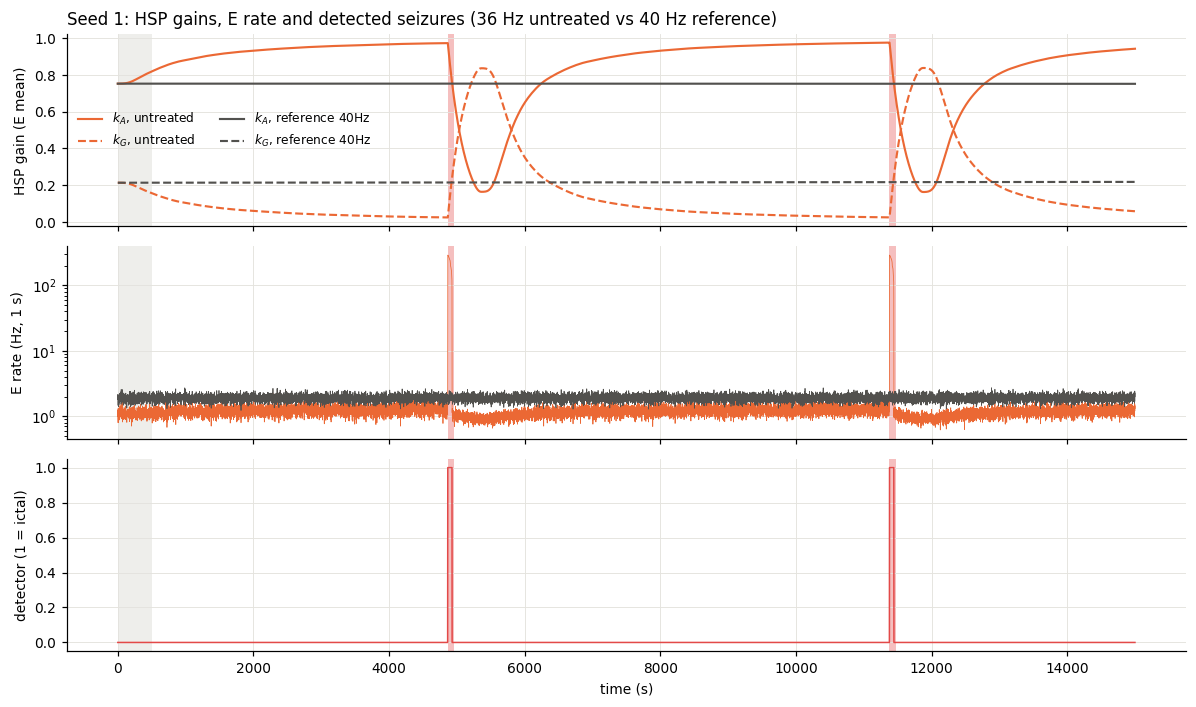

In [4]:
def shade(ax, run, **kw):
    for a, b in run["seizures"]:
        ax.axvspan(a, b + 30, color=ICTAL_C, alpha=0.35, lw=0, **kw)

fig, ax = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
for c in (CYCLIC, STABLE):
    r = RUNS[(1, c)]
    ax[0].plot(r["t"], r["kA"], color=COL[c], lw=1.4, label=f"$k_A$, {c}")
    ax[0].plot(r["t"], r["kG"], color=COL[c], lw=1.4, ls="--", label=f"$k_G$, {c}")
    ax[1].plot(r["t"], np.maximum(r["rE"], 0.05), color=COL[c], lw=0.5, label=c)
ax[1].set_yscale("log"); ax[1].set_ylabel("E rate (Hz, 1 s)")
ax[0].set_ylabel("HSP gain (E mean)"); ax[0].legend(ncol=2, fontsize=8, frameon=False)
r = RUNS[(1, CYCLIC)]
ax[2].plot(r["t"], r["ictal"].astype(int), color=ICTAL_C, lw=1)
ax[2].set_ylabel("detector (1 = ictal)"); ax[2].set_xlabel("time (s)")
for a in ax:
    shade(a, r); a.axvspan(0, SETTLE_S, color="#e4e3de", alpha=0.6, lw=0)
ax[0].set_title("Seed 1: HSP gains, E rate and detected seizures (36 Hz untreated vs 40 Hz reference)", loc="left")
plt.tight_layout(); plt.show()

## 2. AMPA/GABA sensitivity of the E rate (HSP frozen)

At a representative interictal state $(k_A^{ref}, k_G^{ref})$ — the median of the untreated run's interictal samples
— HSP is frozen, every E cell's gains are set to the probe values, and the mean E rate is measured
(`hsp_epileptor_probe.run_probe`: baseline restored, `PROBE_EQUIL_S` discarded, `PROBE_MEASURE_S` measured). The
$\pm$ runs of a pair share the Poisson input realisation (`noise_seed`); two noise seeds give a rough error bar.

$S_A=\partial\bar r_E/\partial k_A$, $S_G=\partial\bar r_E/\partial k_G$ by central differences;
$q_A = k_A^{ref}S_A$, $q_G = -k_G^{ref}S_G$; $w_A = q_A/(q_A+q_G)$, $w_G = q_G/(q_A+q_G)$.

Diagnostics: other states along the seed-1 cycle (deep post-ictal, recovery, early build-up, pre-ictal), and the
median interictal state of seeds 2–5.

In [5]:
def interictal_mask(r, pad=INTERICTAL_PAD_S):
    ok = (r["t"] > SETTLE_S) & ~r["ictal"]
    for a, b in r["seizures"]:
        ok &= ~((r["t"] > a - pad) & (r["t"] < b + pad))
    return ok

def ref_state(seed):
    r = RUNS[(seed, CYCLIC)]; m = interictal_mask(r)
    return float(np.median(r["kA"][m])), float(np.median(r["kG"][m]))

kA_ref, kG_ref = ref_state(PROBE_SEED)
r1 = RUNS[(PROBE_SEED, CYCLIC)]
on1 = [a for a, _ in r1["seizures"] if a > SETTLE_S]
end1 = [b for a, b in r1["seizures"] if a > SETTLE_S]
def state_at(t):
    i = int(np.argmin(np.abs(r1["t"] - t))); return float(r1["kA"][i]), float(r1["kG"][i])
DIAG_STATES = {
    "post-ictal (end + 300 s)": state_at(end1[0] + 300),
    "recovery (end + 1500 s)": state_at(end1[0] + 1500),
    "early build-up (onset - 3000 s)": state_at(on1[0] - 3000),
    "pre-ictal (onset - 300 s)": state_at(on1[0] - 300),
}
print(f"reference state (seed {PROBE_SEED}, median interictal): kA = {kA_ref:.4f}, kG = {kG_ref:.4f}")
for k, v in DIAG_STATES.items():
    print(f"  {k:32s} kA = {v[0]:.4f}, kG = {v[1]:.4f}")

reference state (seed 1, median interictal): kA = 0.9259, kG = 0.0707
  post-ictal (end + 300 s)         kA = 0.2287, kG = 0.7705
  recovery (end + 1500 s)          kA = 0.7984, kG = 0.2014
  early build-up (onset - 3000 s)  kA = 0.9281, kG = 0.0626
  pre-ictal (onset - 300 s)        kA = 0.9717, kG = 0.0250


In [6]:
from joblib import Parallel, delayed
import hsp_epileptor_probe as hp

def plan():
    # (label, seed, kA0, kG0, delta) -> runs: centre + kA +/- + kG +/- for every noise seed
    P = [("main", PROBE_SEED, kA_ref, kG_ref, d) for d in DELTA_FRACS]
    P += [(lab, PROBE_SEED, a, g, DIAG_DELTA) for lab, (a, g) in DIAG_STATES.items()]
    P += [(f"seed {s} median", s, *ref_state(s), DIAG_DELTA) for s in SEEDS if s != PROBE_SEED]
    return P

def runs_for(seed, a, g, d):
    pts = [(a, g), (a * (1 + d), g), (a * (1 - d), g), (a, g * (1 + d)), (a, g * (1 - d))]
    return [(seed, round(x, 6), round(y, 6), n) for x, y in pts for n in PROBE_NOISE_SEEDS]

def key(s, a, g, n):
    return f"{s}|{a:.6f}|{g:.6f}|{n}|{PROBE_FREQ_HZ}|{PROBE_EQUIL_S}|{PROBE_MEASURE_S}"

cache_path = OUT / "probes.json"
CACHE = {} if (RECOMPUTE_PROBES or not cache_path.exists()) else json.loads(cache_path.read_text())
needed = sorted({r for _, s, a, g, d in plan() for r in runs_for(s, a, g, d)})
todo = [r for r in needed if key(*r) not in CACHE]
print(f"{len(needed)} probe runs needed, {len(todo)} to simulate")
if todo:
    res = Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(hp.run_probe)(s, a, g, PROBE_FREQ_HZ, PROBE_EQUIL_S, PROBE_MEASURE_S, n, str(OUT / "probe_work"))
        for s, a, g, n in todo)
    bad = [x for x in res if not x["ok"]]
    if bad:
        raise RuntimeError(bad[0]["traceback"])
    for (s, a, g, n), x in zip(todo, res):
        CACHE[key(s, a, g, n)] = {k: x[k] for k in ("rate", "rate_sd_1s", "max_1s", "runaway")}
    cache_path.write_text(json.dumps(CACHE, indent=1))

114 probe runs needed, 0 to simulate


In [7]:
def rate(s, a, g):
    # per noise seed: mean E rate, NaN if that run ignited (E rate > 10 Hz in a 1 s bin; HSP is frozen,
    # so an ignited run never terminates and is not a local rate response)
    v = [CACHE[key(s, round(a, 6), round(g, 6), n)] for n in PROBE_NOISE_SEEDS]
    return np.array([np.nan if x["runaway"] else x["rate"] for x in v]), sum(x["runaway"] for x in v)

def _mean_se(v):
    v = v[np.isfinite(v)]
    if not len(v):
        return np.nan, np.nan
    return v.mean(), (v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else np.nan)

def sensitivities(s, a, g, d):
    rp, f1 = rate(s, a * (1 + d), g); rm, f2 = rate(s, a * (1 - d), g)
    gp, f3 = rate(s, a, g * (1 + d)); gm, f4 = rate(s, a, g * (1 - d))
    rc, f5 = rate(s, a, g)
    (SA, SA_se), (SG, SG_se) = _mean_se((rp - rm) / (2 * d * a)), _mean_se((gp - gm) / (2 * d * g))
    qA, qG = a * SA, -g * SG
    ok = np.isfinite(qA) and np.isfinite(qG) and SA > 0 and SG < 0
    wA = qA / (qA + qG) if ok else np.nan
    return dict(kA=a, kG=g, delta=d, rate=np.nanmean(rc) if np.isfinite(rc).any() else np.nan,
                SA=SA, SA_se=SA_se, SG=SG, SG_se=SG_se, qA=qA, qG=qG, wA=wA, wG=1 - wA if ok else np.nan,
                n_ignited=f1 + f2 + f3 + f4 + f5, signs_ok=ok)

SENS = [dict(label=lab, seed=s, **sensitivities(s, a, g, d)) for lab, s, a, g, d in plan()]
hdr = f"{'state':34s}{'seed':>5s}{'delta':>7s}{'kA':>7s}{'kG':>7s}{'rate':>7s}{'S_A':>16s}{'S_G':>17s}{'w_A':>7s}{'w_G':>7s}  ignited runs (of 10)"
print(hdr); print("-" * len(hdr))
for x in SENS:
    print(f"{x['label']:34s}{x['seed']:5d}{x['delta']:7.2f}{x['kA']:7.3f}{x['kG']:7.3f}{x['rate']:7.3f}"
          f"{x['SA']:9.3f}±{x['SA_se']:<6.3f}{x['SG']:10.4f}±{x['SG_se']:<6.4f}{x['wA']:7.3f}{x['wG']:7.3f}  {x['n_ignited']}"
          + ("" if x["signs_ok"] else "   <- signs not (+, -): no weight"))

state                              seed  delta     kA     kG   rate             S_A              S_G    w_A    w_G  ignited runs (of 10)
----------------------------------------------------------------------------------------------------------------------------------------
main                                  1   0.01  0.926  0.071  1.252    0.878±0.024    -0.0707±0.0000  0.994  0.006  0
main                                  1   0.02  0.926  0.071  1.252    0.793±0.016    -0.0353±0.0000  0.997  0.003  0
main                                  1   0.05  0.926  0.071  1.252    0.826±0.015     0.0177±0.0530    nan    nan  0   <- signs not (+, -): no weight
main                                  1   0.10  0.926  0.071  1.252      nan±nan      -0.0159±0.0265    nan    nan  2   <- signs not (+, -): no weight
post-ictal (end + 300 s)              1   0.05  0.229  0.771  0.940    0.255±0.001    -0.0013±0.0006  0.983  0.017  0
recovery (end + 1500 s)               1   0.05  0.798  0.201  1.156   

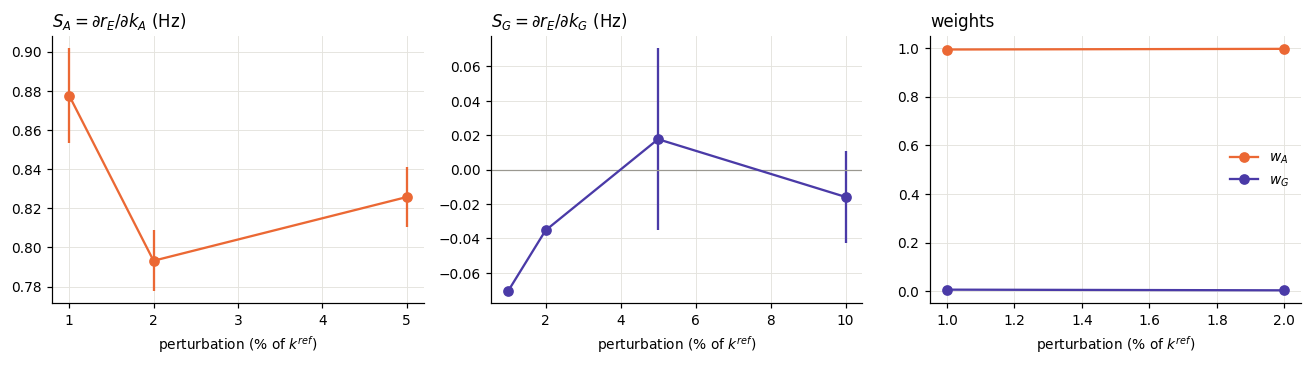

final weights (delta = 2%, seed 1): w_A = 0.9966, w_G = 0.0034; S_A = 0.793 Hz, S_G = -0.0353 Hz


In [8]:
main = [x for x in SENS if x["label"] == "main"]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
d = [x["delta"] * 100 for x in main]
ax[0].errorbar(d, [x["SA"] for x in main], yerr=[x["SA_se"] for x in main], fmt="-o", color=COL[CYCLIC])
ax[0].set_title("$S_A = \\partial r_E/\\partial k_A$ (Hz)", loc="left")
ax[1].errorbar(d, [x["SG"] for x in main], yerr=[x["SG_se"] for x in main], fmt="-o", color="#4a3aa7")
ax[1].axhline(0, color="#9a9890", lw=0.8); ax[1].set_title("$S_G = \\partial r_E/\\partial k_G$ (Hz)", loc="left")
ax[2].plot(d, [x["wA"] for x in main], "-o", label="$w_A$", color=COL[CYCLIC])
ax[2].plot(d, [x["wG"] for x in main], "-o", label="$w_G$", color="#4a3aa7")
ax[2].set_ylim(-0.05, 1.05); ax[2].legend(frameon=False); ax[2].set_title("weights", loc="left")
for a in ax: a.set_xlabel("perturbation (% of $k^{ref}$)")
plt.tight_layout(); plt.show()

FINAL = next(x for x in main if abs(x["delta"] - DELTA_FINAL) < 1e-9)
W_A, W_G = FINAL["wA"], FINAL["wG"]
assert FINAL["signs_ok"], "S_A > 0, S_G < 0 not satisfied at DELTA_FINAL: no weight estimate is forced"
print(f"final weights (delta = {DELTA_FINAL:.0%}, seed {PROBE_SEED}): w_A = {W_A:.4f}, w_G = {W_G:.4f}; "
      f"S_A = {FINAL['SA']:.3f} Hz, S_G = {FINAL['SG']:.4f} Hz")

**Reading the sensitivity table.** At the median interictal state, the GABA gain is already very low, so
inhibition onto E cells is weak and its gain hardly changes the E rate. The derivative-based weight is therefore
almost entirely on AMPA. The diagnostic states show whether this holds across the cycle (it does not at
post-ictal states, where $k_G$ is high). Per the brief, a single fixed pair is used for the first version; the
state dependence is reported, not hidden.

## 3. HSP excitability coordinate $H(t)$ and its critical value $H_c$

In [9]:
def H_of(r):
    return W_A * np.log(np.maximum(r["kA"], K_FLOOR) / kA_ref) - W_G * np.log(np.maximum(r["kG"], K_FLOOR) / kG_ref)

for r in RUNS.values():
    r["H"] = H_of(r)

def Hc_per_seizure(window=PRE_ONSET_WINDOW_S):
    out = []
    for s in SEEDS:
        r = RUNS[(s, CYCLIC)]
        for a, _ in r["seizures"]:
            if a - window < SETTLE_S:
                continue
            m = (r["t"] >= a - window) & (r["t"] < a - PRE_ONSET_GAP_S) & ~r["ictal"]
            out.append(dict(seed=s, onset=a, Hc=float(np.median(r["H"][m]))))
    return out

HCJ = Hc_per_seizure()
H_C = float(np.median([x["Hc"] for x in HCJ]))
print(f"{len(HCJ)} seizures; H_c,j = " + ", ".join(f"{x['Hc']:.4f}" for x in HCJ))
print(f"H_c = median = {H_C:.4f}  (IQR {np.percentile([x['Hc'] for x in HCJ], 25):.4f} - "
      f"{np.percentile([x['Hc'] for x in HCJ], 75):.4f})")

12 seizures; H_c,j = 0.0526, 0.0555, 0.0538, 0.0527, 0.0537, 0.0239, 0.0496, 0.0496, 0.0575, 0.0453, 0.0294, 0.0330
H_c = median = 0.0511  (IQR 0.0422 - 0.0537)


## 4. Epileptor fold and $x_{0,crit}$ (computed from the configured equations)

In [10]:
# fast nullcline f(x1, z) = -x1^3 - 2 x1^2 + 1 - z + I_ext ; fold: df/dx1 = -3 x1^2 - 4 x1 = 0
crit = np.roots([-3.0, -4.0, 0.0])                       # x1 = 0 and x1 = -4/3
X1_SN = float(min(crit.real))                            # interictal-branch fold
g = lambda x1: -x1**3 - 2 * x1**2 + 1 + I_EXT            # z on the fast nullcline
Z_SN = float(g(X1_SN))
X1_UP = float(max(crit.real)); Z_UP = float(g(X1_UP))    # end of the ictal (upper) branch
X0_CRIT = X1_SN - Z_SN / 4.0
print(f"x1_SN = {X1_SN:.5f}, z_SN = {Z_SN:.5f} (I_ext - 5/27 = {I_EXT - 5/27:.5f}), x0_crit = {X0_CRIT:.5f}")
print(f"upper branch exists for z <= {Z_UP:.3f}")

x1_SN = -1.33333, z_SN = 2.91481 (I_ext - 5/27 = 2.91481), x0_crit = -2.06204
upper branch exists for z <= 4.100


## 5. $x_0^{HSP}(t)$, $D_{seizure}$, $D_H$

No second anchor with a justified Epileptor value exists in the project (the 40 Hz reference is stable, but nothing
assigns it a specific $x_0$). Following the brief, $\beta=1$ is used **only as a visual affine embedding**: the
absolute $x_0$ scale away from $x_{0,crit}$ is uncalibrated, while the sign of $D_{seizure}$ (and $D_H$, which is
calibration-free) is meaningful.

In [11]:
for r in RUNS.values():
    r["x0"] = X0_CRIT + BETA * (r["H"] - H_C)
    r["D"] = X0_CRIT - r["x0"]
    r["DH"] = H_C - r["H"]

## 6. Reconstruct $z(t)$

$x_1(t)$: lower (interictal) branch of $f(x_1,z)=0$ when the detector says interictal, upper branch when ictal
(held at the fold of that branch if it does not exist at the current $z$; flagged). $z$ is integrated with an implicit (backward) Euler
step of `Z_DT_S`, solved exactly by bisection (the right-hand side is monotone in $z$), with $x_0$ linearly
interpolated between the 1 s samples. An explicit step is not used: near the fold the interictal fixed point lies
only $\approx 2D^2$ above $z_{SN}$ and $\partial x_1/\partial z$ diverges, so explicit steps chatter across the fold. $z(0)$: the interictal fixed point for $x_0(0)$ (intersection of the slow nullcline
with the lower branch), or the fold if none exists; the first `SETTLE_S` are excluded anyway.

**Time scale.** With $r=0.35$ s$^{-1}$, $z$ relaxes in $1/r\approx2.9$ s, three orders of magnitude faster than
HSP: between seizures $z$ sits at its quasi-static value $z^*(x_0)$.

In [12]:
def cubic_real_roots(c):
    # real roots of x^3 + 2x^2 + c = 0  (f = 0 with c = z - 1 - I_ext), sorted
    a = 2.0
    p, q = -a * a / 3.0, 2 * a**3 / 27.0 + c
    disc = (q / 2) ** 2 + (p / 3) ** 3
    if disc < 0:                       # three real roots
        m = 2 * math.sqrt(-p / 3); th = math.acos(max(-1.0, min(1.0, 3 * q / (p * m)))) / 3
        return sorted(m * math.cos(th - 2 * math.pi * k / 3) - a / 3 for k in range(3))
    u = math.copysign(abs(-q / 2 + math.sqrt(disc)) ** (1 / 3), -q / 2 + math.sqrt(disc))
    v = math.copysign(abs(-q / 2 - math.sqrt(disc)) ** (1 / 3), -q / 2 - math.sqrt(disc))
    return [u + v - a / 3]

def x1_branch(z, ictal):
    rts = cubic_real_roots(z - 1 - I_EXT)
    if ictal:
        up = [x for x in rts if x >= X1_UP - 1e-9]
        return (max(up), False) if up else (X1_UP, True)
    lo = [x for x in rts if x <= X1_SN + 1e-9]
    return (min(lo), False) if lo else (X1_SN, True)

def z_fixed_point(x0):
    # interictal fixed point: lower branch meets z = 4 (x1 - x0)  ->  solve g(x1) = 4 (x1 - x0), x1 <= x1_SN
    rts = np.roots([-1.0, -2.0, -4.0, 1 + I_EXT + 4 * x0])
    lo = [x.real for x in rts if abs(x.imag) < 1e-9 and x.real <= X1_SN]
    return 4 * (min(lo) - x0) if lo else Z_SN

def h_rhs(z, x0, ictal):
    x1, _ = x1_branch(z, ictal)
    return 4 * (x1 - x0) - z - (0.1 * z**7 if z < 0 else 0.0)

def implicit_step(z, x0, ictal, dt, rr):
    # backward Euler: solve F(y) = y - z - dt*rr*h(y) = 0. h is continuous and strictly decreasing in y
    # (both branches and the fold clamps), so F is strictly increasing: bisection is exact and stable.
    F = lambda y: y - z - dt * rr * h_rhs(y, x0, ictal)
    lo, hi = z - 1.0, z + 1.0
    while F(lo) > 0: lo -= 2 * (hi - lo)
    while F(hi) < 0: hi += 2 * (hi - lo)
    for _ in range(50):
        mid = 0.5 * (lo + hi)
        if F(mid) > 0: hi = mid
        else: lo = mid
    return 0.5 * (lo + hi)

def integrate_z(r, dt=Z_DT_S, z0=None, rr=R_PER_S):
    t, x0, ic = r["t"], r["x0"], r["ictal"]
    z = z_fixed_point(x0[0]) if z0 is None else z0
    nsub = max(1, int(round(1.0 / dt)))
    Z = np.empty(len(t)); X1 = np.empty(len(t)); FLAG = np.zeros(len(t), bool)
    for i in range(len(t)):
        Z[i] = z
        X1[i], FLAG[i] = x1_branch(z, bool(ic[i]))
        xa, xb = x0[i], x0[min(i + 1, len(t) - 1)]
        for k in range(nsub):
            z = implicit_step(z, xa + (xb - xa) * (k + 1) / nsub, bool(ic[i]), 1.0 / nsub, rr)
    return Z, X1, FLAG

for r in RUNS.values():
    r["z"], r["x1"], r["x1_flag"] = integrate_z(r)
    r["Dz"] = r["z"] - Z_SN

# convergence check on one cyclic run
rc = RUNS[(1, CYCLIC)]
zf, _, _ = integrate_z(rc, dt=Z_DT_S / 5)
m = rc["t"] > SETTLE_S
dzc = np.abs(rc["z"] - zf)
mi_ = interictal_mask(rc)
print(f"convergence (dt = {Z_DT_S} vs {Z_DT_S/5} s): max |dz| interictal = {dzc[mi_].max():.2e}, "
      f"all samples = {dzc[m].max():.2e}, 99th pct = {np.percentile(dzc[m], 99):.2e} (z range {rc['z'][m].min():.2f} .. {rc['z'][m].max():.2f})")
for c in CONDITIONS:
    fl = np.mean([np.mean(RUNS[(s, c)]["x1_flag"][RUNS[(s, c)]["t"] > SETTLE_S]) for s in SEEDS])
    print(f"{c:15s} share of samples with x1 held at a fold (branch missing): {fl:.3f}")

convergence (dt = 0.1 vs 0.02 s): max |dz| interictal = 1.03e-05, all samples = 5.40e-02, 99th pct = 7.86e-06 (z range 2.89 .. 9.23)
untreated       share of samples with x1 held at a fold (branch missing): 0.058
reference 40Hz  share of samples with x1 held at a fold (branch missing): 0.000
benzo (k=1.0)   share of samples with x1 held at a fold (branch missing): 0.731
DBS 20pA        share of samples with x1 held at a fold (branch missing): 0.003
DBS 60pA        share of samples with x1 held at a fold (branch missing): 0.000
DBS 100pA       share of samples with x1 held at a fold (branch missing): 0.000
DBS 150pA       share of samples with x1 held at a fold (branch missing): 0.000
DBS 200pA       share of samples with x1 held at a fold (branch missing): 0.000
DBS 250pA       share of samples with x1 held at a fold (branch missing): 0.000
DBS 300pA       share of samples with x1 held at a fold (branch missing): 0.000


### Figures 2–5 — $H$, $x_0^{HSP}$, distances and $z$ over time (seed 1, untreated vs reference)

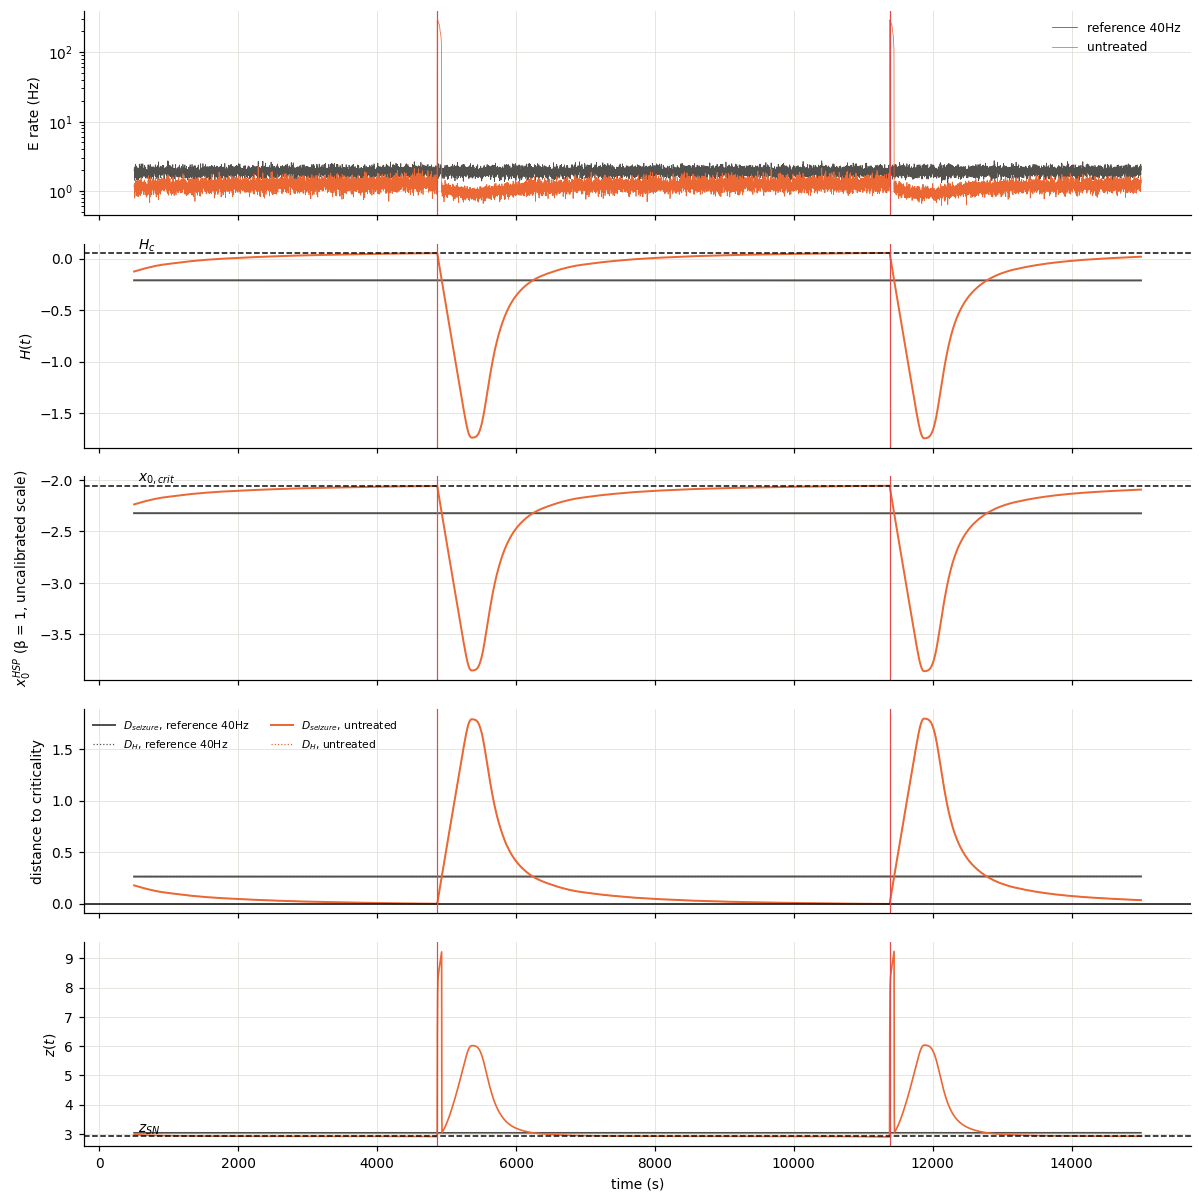

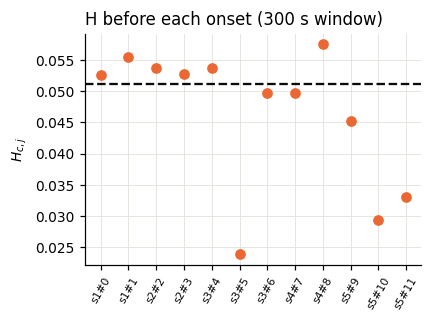

In [13]:
fig, ax = plt.subplots(5, 1, figsize=(11, 11), sharex=True)
for c in (STABLE, CYCLIC):
    r = RUNS[(1, c)]; m = r["t"] > SETTLE_S
    ax[0].plot(r["t"][m], np.maximum(r["rE"][m], 0.05), color=COL[c], lw=0.5, label=c)
    ax[1].plot(r["t"][m], r["H"][m], color=COL[c], lw=1.3, label=c)
    ax[2].plot(r["t"][m], r["x0"][m], color=COL[c], lw=1.3)
    ax[3].plot(r["t"][m], r["D"][m], color=COL[c], lw=1.3, label=f"$D_{{seizure}}$, {c}")
    ax[3].plot(r["t"][m], r["DH"][m], color=COL[c], lw=0.8, ls=":", label=f"$D_H$, {c}")
    ax[4].plot(r["t"][m], r["z"][m], color=COL[c], lw=1.1)
ax[0].set_yscale("log"); ax[0].set_ylabel("E rate (Hz)"); ax[0].legend(frameon=False, fontsize=8)
ax[1].axhline(H_C, color=CRIT_C, ls="--", lw=1); ax[1].set_ylabel("$H(t)$"); ax[1].text(SETTLE_S, H_C, " $H_c$", va="bottom")
ax[2].axhline(X0_CRIT, color=CRIT_C, ls="--", lw=1); ax[2].set_ylabel("$x_0^{HSP}$ (β = 1, uncalibrated scale)")
ax[2].text(SETTLE_S, X0_CRIT, " $x_{0,crit}$", va="bottom")
ax[3].axhline(0, color=CRIT_C, lw=1); ax[3].set_ylabel("distance to criticality"); ax[3].legend(frameon=False, fontsize=7, ncol=2)
ax[4].axhline(Z_SN, color=CRIT_C, ls="--", lw=1); ax[4].set_ylabel("$z(t)$"); ax[4].text(SETTLE_S, Z_SN, " $z_{SN}$", va="bottom")
ax[4].set_xlabel("time (s)")
for a in ax:
    for on, _ in RUNS[(1, CYCLIC)]["seizures"]:
        a.axvline(on, color=ICTAL_C, lw=0.8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(np.arange(len(HCJ)), [x["Hc"] for x in HCJ], "o", color=COL[CYCLIC])
ax.axhline(H_C, color=CRIT_C, ls="--"); ax.set_xticks(range(len(HCJ)))
ax.set_xticklabels([f"s{x['seed']}#{i}" for i, x in enumerate(HCJ)], rotation=60, fontsize=7)
ax.set_ylabel("$H_{c,j}$"); ax.set_title(f"H before each onset ({PRE_ONSET_WINDOW_S:.0f} s window)", loc="left")
plt.tight_layout(); plt.show()

## 7. Main trajectory: $(x_0^{HSP}, z)$

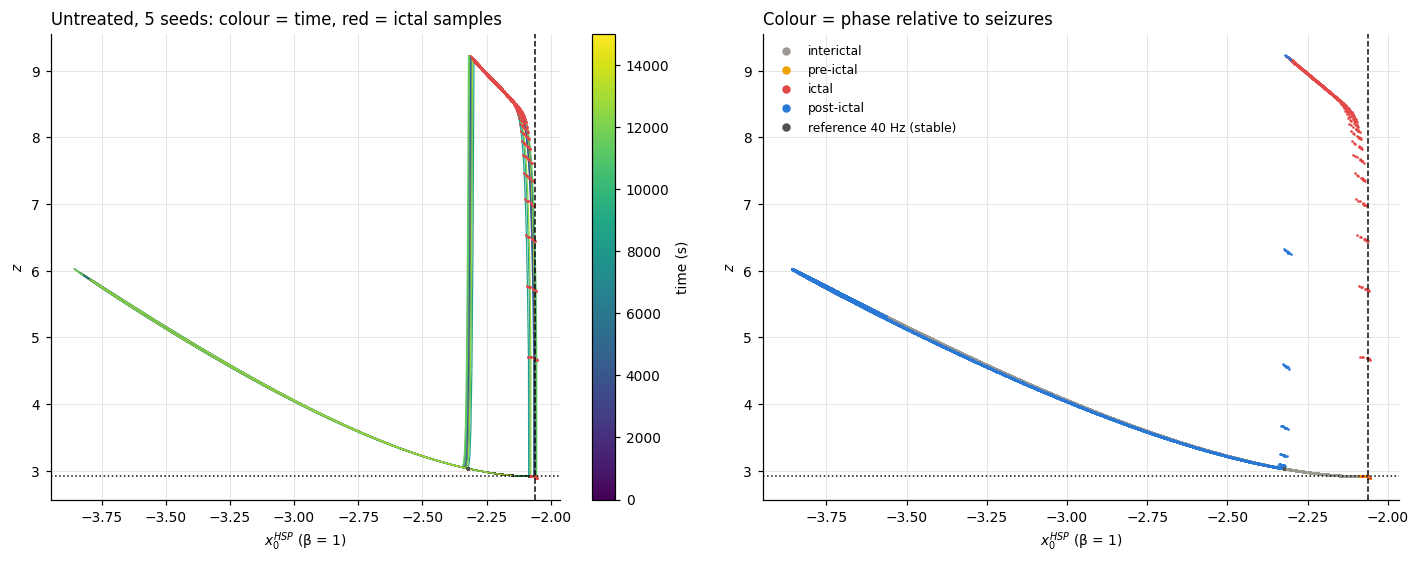

In [14]:
def phase_labels(r, pre=COMPARE_WINDOW_S, post=POSTICTAL_S):
    lab = np.full(len(r["t"]), "interictal", dtype=object)
    for a, b in r["seizures"]:
        lab[(r["t"] >= a - pre) & (r["t"] < a)] = "pre-ictal"
        lab[(r["t"] >= b) & (r["t"] < b + post)] = "post-ictal"
    lab[r["ictal"]] = "ictal"
    lab[r["t"] <= SETTLE_S] = "settle"
    return lab

PH_COL = {"interictal": "#9a9890", "pre-ictal": "#eda100", "ictal": ICTAL_C, "post-ictal": "#2a78d6"}
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for s in SEEDS:
    r = RUNS[(s, CYCLIC)]; m = r["t"] > SETTLE_S
    pts = np.c_[r["x0"][m], r["z"][m]]
    lc = LineCollection(np.stack([pts[:-1], pts[1:]], 1), cmap="viridis", lw=0.8,
                        norm=plt.Normalize(0, 15000))
    lc.set_array(r["t"][m][:-1]); ax[0].add_collection(lc)
    ax[0].plot(r["x0"][r["ictal"]], r["z"][r["ictal"]], ".", ms=2, color=ICTAL_C)
    lab = phase_labels(r)
    for p, c in PH_COL.items():
        k = (lab == p)
        ax[1].plot(r["x0"][k], r["z"][k], ".", ms=1.5, color=c, label=p if s == 1 else None)
r = RUNS[(1, STABLE)]; m = r["t"] > SETTLE_S
for a in ax:
    a.plot(r["x0"][m], r["z"][m], ".", ms=1.5, color=COL[STABLE], label="reference 40 Hz (stable)" if a is ax[1] else None)
    a.axvline(X0_CRIT, color=CRIT_C, ls="--", lw=1); a.axhline(Z_SN, color=CRIT_C, ls=":", lw=1)
    a.set_xlabel("$x_0^{HSP}$ (β = 1)"); a.set_ylabel("$z$")
    a.autoscale()
cb = plt.colorbar(lc, ax=ax[0]); cb.set_label("time (s)")
ax[0].set_title("Untreated, 5 seeds: colour = time, red = ictal samples", loc="left")
ax[1].set_title("Colour = phase relative to seizures", loc="left"); ax[1].legend(markerscale=6, frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Canonical Epileptor phase plane $(x_1, z)$
Fast nullcline $z=-x_1^3-2x_1^2+1+I_{ext}$ and slow nullclines $z=4(x_1-x_0)$ for representative $x_0^{HSP}$ values
taken from the untreated trajectory: deep post-ictal, mid-interictal, pre-ictal (median over the pre-onset windows),
and $x_{0,crit}$.

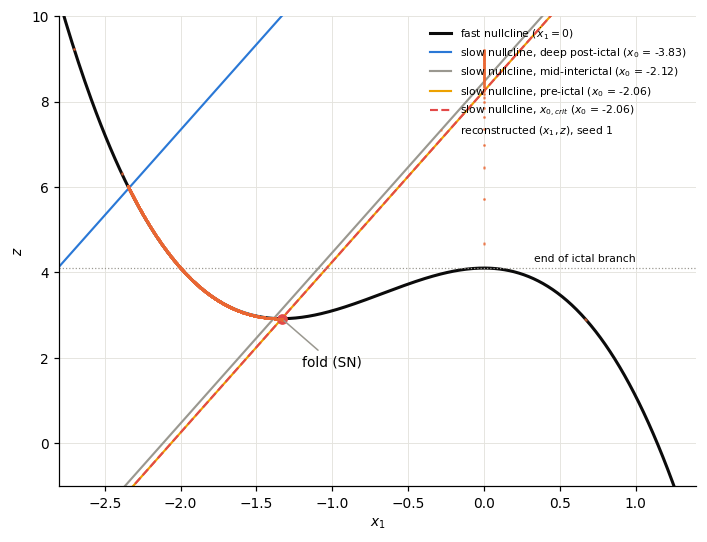

In [15]:
allc = [RUNS[(s, CYCLIC)] for s in SEEDS]
def pooled(key, sel):
    return np.concatenate([r[key][sel(r)] for r in allc])
x0_post = np.percentile(pooled("x0", lambda r: phase_labels(r) == "post-ictal"), 5)
x0_inter = np.median(pooled("x0", lambda r: phase_labels(r) == "interictal"))
x0_pre = np.median(pooled("x0", lambda r: phase_labels(r) == "pre-ictal"))
x1g = np.linspace(-2.8, 1.4, 400)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(x1g, g(x1g), color=CRIT_C, lw=2, label="fast nullcline ($\\dot x_1=0$)")
for v, lab, c in ((x0_post, "deep post-ictal", "#2a78d6"), (x0_inter, "mid-interictal", "#9a9890"),
                  (x0_pre, "pre-ictal", "#eda100"), (X0_CRIT, "$x_{0,crit}$", ICTAL_C)):
    ax.plot(x1g, 4 * (x1g - v), color=c, lw=1.4, ls="--" if lab.startswith("$") else "-",
            label=f"slow nullcline, {lab} ($x_0$ = {v:.2f})")
ax.plot([X1_SN], [Z_SN], "o", color=ICTAL_C); ax.annotate("fold (SN)", (X1_SN, Z_SN), xytext=(-1.2, 1.8),
            arrowprops=dict(arrowstyle="-", color="#9a9890"))
ax.axhline(Z_UP, color="#9a9890", lw=0.8, ls=":"); ax.text(1.0, Z_UP + 0.15, "end of ictal branch", fontsize=7, ha="right")
r = RUNS[(1, CYCLIC)]; m = r["t"] > SETTLE_S
ax.plot(r["x1"][m], r["z"][m], ".", ms=1.5, color=COL[CYCLIC], alpha=0.5, label="reconstructed $(x_1, z)$, seed 1")
ax.set_xlim(-2.8, 1.4); ax.set_ylim(-1, 10); ax.set_xlabel("$x_1$"); ax.set_ylabel("$z$")
ax.legend(fontsize=7, frameon=False, loc="upper right"); plt.tight_layout(); plt.show()

## 8. Stable vs cyclic: identical mapping for all conditions

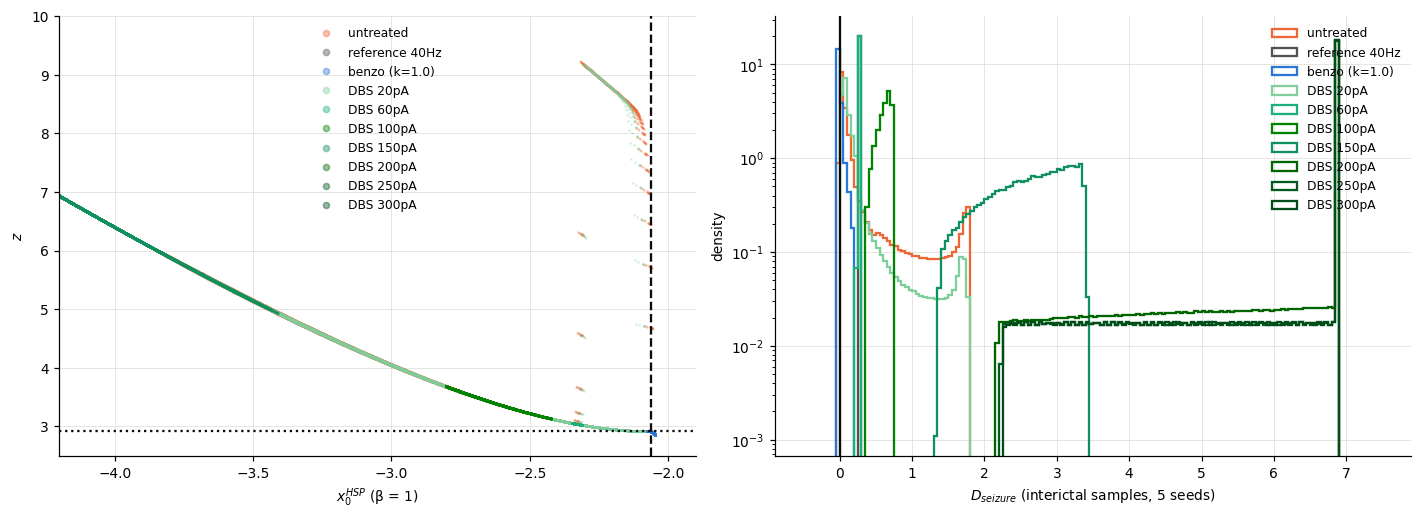

untreated       interictal D: min -0.007, 1st pct -0.004, median +0.059, share D < 0: 0.044
reference 40Hz  interictal D: min +0.258, 1st pct +0.259, median +0.262, share D < 0: 0.000
benzo (k=1.0)   interictal D: min -0.016, 1st pct -0.016, median -0.011, share D < 0: 0.731
DBS 20pA        interictal D: min +0.024, 1st pct +0.026, median +0.082, share D < 0: 0.000
DBS 60pA        interictal D: min +0.250, 1st pct +0.250, median +0.257, share D < 0: 0.000
DBS 100pA       interictal D: min +0.360, 1st pct +0.391, median +0.636, share D < 0: 0.000
DBS 150pA       interictal D: min +1.347, 1st pct +1.471, median +2.719, share D < 0: 0.000
DBS 200pA       interictal D: min +2.165, 1st pct +2.716, median +6.868, share D < 0: 0.000
DBS 250pA       interictal D: min +2.229, 1st pct +2.811, median +6.868, share D < 0: 0.000
DBS 300pA       interictal D: min +2.252, 1st pct +2.834, median +6.868, share D < 0: 0.000


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for c in CONDITIONS:
    for s in SEEDS:
        r = RUNS[(s, c)]; m = r["t"] > SETTLE_S
        ax[0].plot(r["x0"][m], r["z"][m], ".", ms=1, color=COL[c], alpha=0.4, label=c if s == 1 else None)
    D = np.concatenate([RUNS[(s, c)]["D"][interictal_mask(RUNS[(s, c)])] for s in SEEDS])
    ax[1].hist(D, bins=160, range=(-0.5, 7.5), histtype="step", lw=1.5, color=COL[c], density=True, label=c)
ax[0].set_xlim(-4.2, -1.9); ax[0].set_ylim(2.5, 10)   # DBS 300 pA lies far to the left (off scale)
ax[1].set_yscale("log")
ax[0].axvline(X0_CRIT, color=CRIT_C, ls="--"); ax[0].axhline(Z_SN, color=CRIT_C, ls=":")
ax[0].set_xlabel("$x_0^{HSP}$ (β = 1)"); ax[0].set_ylabel("$z$"); ax[0].legend(markerscale=8, frameon=False, fontsize=8)
ax[1].axvline(0, color=CRIT_C); ax[1].set_xlabel("$D_{seizure}$ (interictal samples, 5 seeds)"); ax[1].set_ylabel("density")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
for c in CONDITIONS:
    D = np.concatenate([RUNS[(s, c)]["D"][interictal_mask(RUNS[(s, c)])] for s in SEEDS])
    print(f"{c:15s} interictal D: min {D.min():+.3f}, 1st pct {np.percentile(D, 1):+.3f}, median {np.median(D):+.3f}, "
          f"share D < 0: {np.mean(D < 0):.3f}")

## 9. Quantitative tests

In [17]:
def loo_Hc(seed, onset, window=PRE_ONSET_WINDOW_S):
    # H_c without the seizure being evaluated (avoids circularity)
    v = [x["Hc"] for x in Hc_per_seizure(window) if not (x["seed"] == seed and x["onset"] == onset)]
    return float(np.median(v))

rows = []
for s in SEEDS:
    r = RUNS[(s, CYCLIC)]
    prev_end = SETTLE_S
    for a, b in r["seizures"]:
        if a - MATCHED_OFFSET_S - COMPARE_WINDOW_S < prev_end or a < SETTLE_S + COMPARE_WINDOW_S:
            prev_end = b; continue
        hc = loo_Hc(s, a)
        Dl = (hc - r["H"]) * BETA                              # D_seizure with leave-one-out H_c
        pre = (r["t"] >= a - COMPARE_WINDOW_S) & (r["t"] < a - PRE_ONSET_GAP_S)
        mat = (r["t"] >= a - MATCHED_OFFSET_S - COMPARE_WINDOW_S) & (r["t"] < a - MATCHED_OFFSET_S)
        post = (r["t"] >= b) & (r["t"] < b + POSTICTAL_S)
        span = (r["t"] > prev_end) & (r["t"] < a)
        neg = np.flatnonzero(span & (Dl <= 0))
        first_cross = a - r["t"][neg[0]] if len(neg) else np.nan
        rows.append(dict(seed=s, onset=a, D_pre=np.median(Dl[pre]), D_matched=np.median(Dl[mat]),
                         D_at_onset=Dl[np.flatnonzero(r["t"] < a)[-1]], lead_s=first_cross,
                         frac_neg_before=np.mean(Dl[span] <= 0),
                         dD_post=np.median(Dl[post][-60:]) - np.median(Dl[post][:30])))
        prev_end = b

print(f"{'seed':>4s}{'onset':>8s}{'D pre':>9s}{'D matched':>11s}{'D@onset':>9s}{'first D<=0 (s before)':>23s}{'share D<=0':>12s}{'post-ictal dD':>15s}")
for x in rows:
    print(f"{x['seed']:4d}{x['onset']:8.0f}{x['D_pre']:9.3f}{x['D_matched']:11.3f}{x['D_at_onset']:9.3f}"
          f"{x['lead_s']:23.0f}{x['frac_neg_before']:12.3f}{x['dD_post']:15.3f}")
pre = np.array([x["D_pre"] for x in rows]); mat = np.array([x["D_matched"] for x in rows])
print(f"\nQ3: D <= 0 reached before onset in {np.sum(np.isfinite([x['lead_s'] for x in rows]))}/{len(rows)} seizures; "
      f"D at onset: median {np.median([x['D_at_onset'] for x in rows]):+.3f}")
print(f"Q4: D in last {COMPARE_WINDOW_S:.0f} s vs {MATCHED_OFFSET_S:.0f} s earlier: median {np.median(pre):+.3f} vs "
      f"{np.median(mat):+.3f}; smaller before onset in {np.sum(pre < mat)}/{len(rows)}; "
      f"Wilcoxon p = {stats.wilcoxon(pre, mat).pvalue:.4f}")
print(f"Q5: D change over the first {POSTICTAL_S:.0f} s after seizures (end of window - start): "
      f"median {np.median([x['dD_post'] for x in rows]):+.3f}  (positive = moving away from the fold)")

seed   onset    D pre  D matched  D@onset  first D<=0 (s before)  share D<=0  post-ictal dD
   1    4865   -0.003      0.013   -0.004                    555       0.127          1.363
   1   11379   -0.006      0.007   -0.007                    984       0.153          1.378
   2    4986   -0.004      0.012   -0.005                    688       0.153          1.351
   2   10884   -0.003      0.014   -0.004                    521       0.089          1.355
   3    4841   -0.004      0.013   -0.005                    620       0.143          1.349
   3    8620    0.029      0.105    0.025                    nan       0.000          1.279
   3   13999    0.003      0.026    0.002                    nan       0.000          1.348
   4    4630    0.003      0.023    0.002                    nan       0.000          1.365
   4   11221   -0.008      0.005   -0.009                   1148       0.176          1.383
   5    4260    0.007      0.029    0.006                    nan       0.000    

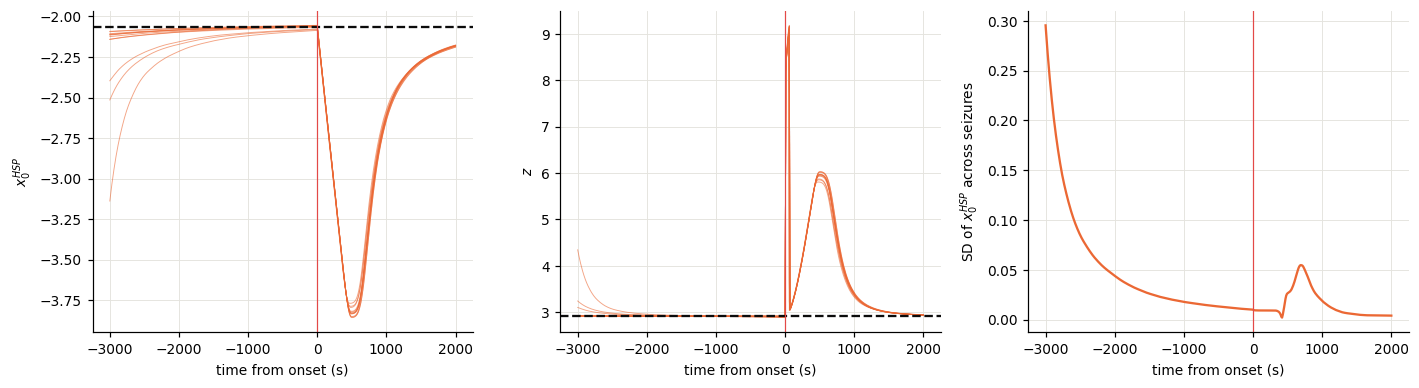

Q1: 12 seizures; across-seizure SD of x0 at -1000 s: 0.018, at -100 s: 0.010, at +500 s: 0.026; range of x0 over the cycle: -3.86 .. -2.05


In [18]:
# Q1: repeatability of the loop -- onset-aligned x0 and z across all seizures
lags = np.arange(-3000, 2001, 10)
X0A, ZA = [], []
for s in SEEDS:
    r = RUNS[(s, CYCLIC)]
    for a, _ in r["seizures"]:
        idx = np.searchsorted(r["t"], a + lags)
        ok = (a + lags > SETTLE_S) & (idx < len(r["t"]))
        x0v = np.full(len(lags), np.nan); zv = np.full(len(lags), np.nan)
        x0v[ok] = r["x0"][idx[ok]]; zv[ok] = r["z"][idx[ok]]
        X0A.append(x0v); ZA.append(zv)
X0A, ZA = np.array(X0A), np.array(ZA)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for v in X0A: ax[0].plot(lags, v, color=COL[CYCLIC], lw=0.6, alpha=0.6)
ax[0].axhline(X0_CRIT, color=CRIT_C, ls="--"); ax[0].set_xlabel("time from onset (s)"); ax[0].set_ylabel("$x_0^{HSP}$")
for v in ZA: ax[1].plot(lags, v, color=COL[CYCLIC], lw=0.6, alpha=0.6)
ax[1].axhline(Z_SN, color=CRIT_C, ls="--"); ax[1].set_xlabel("time from onset (s)"); ax[1].set_ylabel("$z$")
ax[2].plot(lags, np.nanstd(X0A, 0), color=COL[CYCLIC]); ax[2].set_xlabel("time from onset (s)")
ax[2].set_ylabel("SD of $x_0^{HSP}$ across seizures")
for a in ax: a.axvline(0, color=ICTAL_C, lw=0.8)
plt.tight_layout(); plt.show()
print(f"Q1: {len(X0A)} seizures; across-seizure SD of x0 at -1000 s: {np.nanstd(X0A[:, lags == -1000]):.3f}, "
      f"at -100 s: {np.nanstd(X0A[:, lags == -100]):.3f}, at +500 s: {np.nanstd(X0A[:, lags == 500]):.3f}; "
      f"range of x0 over the cycle: {np.nanmin(X0A):.2f} .. {np.nanmax(X0A):.2f}")

## 10. Robustness: perturbation size, pre-onset window, $z(0)$, and $r$

In [19]:
print("weights vs perturbation size (seed 1, median interictal state):")
for x in main:
    print(f"  delta {x['delta']:.2f}: S_A {x['SA']:.3f} ± {x['SA_se']:.3f}, S_G {x['SG']:.4f} ± {x['SG_se']:.4f}, w_A {x['wA']:.4f}, w_G {x['wG']:.4f}")
print("\nweights at other states / seeds (delta = %.2f):" % DIAG_DELTA)
for x in SENS:
    if x["label"] != "main":
        print(f"  {x['label']:34s} kA {x['kA']:.3f} kG {x['kG']:.3f} rate {x['rate']:.3f}: w_A {x['wA']:.3f}, w_G {x['wG']:.3f}"
              + (f"  ({x['n_ignited']} of 10 runs ignited a seizure)" if x["n_ignited"] else ""))

print("\nH_c vs pre-onset window:")
for w in PRE_ONSET_WINDOWS_ROBUST:
    v = [x["Hc"] for x in Hc_per_seizure(w)]
    print(f"  W = {w:5.0f} s: H_c = {np.median(v):.4f} (n = {len(v)}, IQR {np.percentile(v, 25):.4f} .. {np.percentile(v, 75):.4f})")

print("\nz(0) sensitivity (seed 1 untreated): time until z agrees with the default z(0) run")
rc = RUNS[(1, CYCLIC)]
for z0 in (Z_SN, Z_SN + 2.0, -0.5):
    zz, _, _ = integrate_z(rc, z0=z0)
    dz = np.abs(zz - rc["z"])
    t_conv = rc["t"][np.flatnonzero(dz > 1e-3)[-1] + 1] if np.any(dz > 1e-3) else 0.0
    print(f"  z0 = {z0:+.2f}: |dz| < 1e-3 from t = {t_conv:.0f} s on (settling period: {SETTLE_S:.0f} s)")

print("\nr sensitivity (seed 1 untreated, interictal samples): z vs quasi-static z*(x0)")
qs = np.array([z_fixed_point(v) for v in rc["x0"]])
mi = interictal_mask(rc)
for rr in (R_PER_S, R_PER_S / 10, R_PER_S / 100):
    zz, _, _ = integrate_z(rc, rr=rr)
    e_ = np.abs(zz[mi] - qs[mi])
    print(f"  r = {rr:.4f} /s (1/r = {1/rr:7.1f} s): |z - z*| interictal median {np.median(e_):.3f}, 99th pct {np.percentile(e_, 99):.3f}")

weights vs perturbation size (seed 1, median interictal state):
  delta 0.01: S_A 0.878 ± 0.024, S_G -0.0707 ± 0.0000, w_A 0.9939, w_G 0.0061
  delta 0.02: S_A 0.793 ± 0.016, S_G -0.0353 ± 0.0000, w_A 0.9966, w_G 0.0034
  delta 0.05: S_A 0.826 ± 0.015, S_G 0.0177 ± 0.0530, w_A nan, w_G nan
  delta 0.10: S_A nan ± nan, S_G -0.0159 ± 0.0265, w_A nan, w_G nan

weights at other states / seeds (delta = 0.05):
  post-ictal (end + 300 s)           kA 0.229 kG 0.771 rate 0.940: w_A 0.983, w_G 0.017
  recovery (end + 1500 s)            kA 0.798 kG 0.201 rate 1.156: w_A 0.998, w_G 0.002
  early build-up (onset - 3000 s)    kA 0.928 kG 0.063 rate 1.254: w_A 0.989, w_G 0.011
  pre-ictal (onset - 300 s)          kA 0.972 kG 0.025 rate 1.285: w_A nan, w_G nan  (5 of 10 runs ignited a seizure)
  seed 2 median                      kA 0.929 kG 0.068 rate 1.246: w_A 0.994, w_G 0.006  (1 of 10 runs ignited a seizure)
  seed 3 median                      kA 0.914 kG 0.086 rate 1.228: w_A 0.996, w_G 0.004


  z0 = +2.91: |dz| < 1e-3 from t = 4 s on (settling period: 500 s)


  z0 = +4.91: |dz| < 1e-3 from t = 6 s on (settling period: 500 s)


  z0 = -0.50: |dz| < 1e-3 from t = 8 s on (settling period: 500 s)

r sensitivity (seed 1 untreated, interictal samples): z vs quasi-static z*(x0)


  r = 0.3500 /s (1/r =     2.9 s): |z - z*| interictal median 0.000, 99th pct 0.017


  r = 0.0350 /s (1/r =    28.6 s): |z - z*| interictal median 0.000, 99th pct 0.157


  r = 0.0035 /s (1/r =   285.7 s): |z - z*| interictal median 0.000, 99th pct 1.026


## 11. Interpretation (filled in from the outputs above)

See the summary cell below, generated from the computed quantities.

In [20]:
x_main = FINAL
cyc_D = np.concatenate([RUNS[(s, CYCLIC)]["D"][interictal_mask(RUNS[(s, CYCLIC)])] for s in SEEDS])
stb_D = np.concatenate([RUNS[(s, STABLE)]["D"][interictal_mask(RUNS[(s, STABLE)])] for s in SEEDS])
print("SUMMARY")
print(f"* Weights: w_A = {W_A:.3f}, w_G = {W_G:.3f} (S_A = {x_main['SA']:.3f} Hz, S_G = {x_main['SG']:.4f} Hz at kA = {kA_ref:.3f}, kG = {kG_ref:.3f}).")
print(f"* Epileptor fold: x0_crit = {X0_CRIT:.4f}, z_SN = {Z_SN:.4f}; H_c = {H_C:.4f} from {len(HCJ)} seizures.")
print(f"* Stable (40 Hz) interictal D: median {np.median(stb_D):+.3f}, min {stb_D.min():+.3f}; cyclic: median {np.median(cyc_D):+.3f}, "
      f"share D<0 {np.mean(cyc_D < 0):.3f}.")
print(f"* Pre-onset D (leave-one-out H_c) {np.median(pre):+.3f} vs matched {np.median(mat):+.3f} "
      f"({np.sum(pre < mat)}/{len(rows)} seizures smaller before onset).")

SUMMARY
* Weights: w_A = 0.997, w_G = 0.003 (S_A = 0.793 Hz, S_G = -0.0353 Hz at kA = 0.926, kG = 0.071).
* Epileptor fold: x0_crit = -2.0620, z_SN = 2.9148; H_c = 0.0511 from 12 seizures.
* Stable (40 Hz) interictal D: median +0.262, min +0.258; cyclic: median +0.059, share D<0 0.044.
* Pre-onset D (leave-one-out H_c) +0.000 vs matched +0.018 (12/12 seizures smaller before onset).


### Interpretation

**Answers to the six questions** (numbers in the outputs above):
1. *Repeatable loop.* Yes. Every untreated cycle traces the same path in $(x_0^{HSP}, z)$: a fast jump far into the
   subcritical side after each seizure (HSP collapses $k_A$), a slow return over thousands of seconds, and a long
   approach that flattens just at $x_{0,crit}$. Across the 12 seizures, $x_0^{HSP}$ differs by only ~0.01–0.03 at a
   given lag, against a cycle range of ~1.8.
2. *Stable condition.* Yes. The 40 Hz reference (and DBS 60 pA) sits in a compact subcritical region
   ($D_{seizure}\approx +0.26$) and never approaches the fold.
3. *Approach/crossing before onset.* $x_0^{HSP}$ reaches the critical value at onset (median $D$ at onset ≈ 0 with a
   leave-one-out $H_c$). In half of the seizures it had crossed it 9–19 min earlier, without a seizure; in the other half
   onset came while $D$ was still slightly positive (up to ~0.025).
4. *Smaller before seizures.* Yes: in all 12 seizures, $D$ in the last 5 min is smaller than 25–30 min earlier
   (Wilcoxon $p$ = 0.0005). But the plateau is flat, so $D$ is near zero for a long time: this is a slow risk
   state, not a precise onset time (the same conclusion as the LFP power analysis).
5. *Post-ictal direction.* Yes: in the first 10 min after each seizure, $D$ increases by ~1.35, moving far away from the
   fold. The same structure as the Epileptor's post-ictal refractoriness, but here it comes from HSP, not from $z$.
6. *Robustness.* $w_A$ is 0.98–1.00 across perturbation sizes, cycle states and seeds; $H_c$ changes by < 0.002 for
   pre-onset windows of 100–600 s; $z(0)$ is forgotten within ~10 s. Perturbations of 10% or probes at the pre-ictal state
   **ignite seizures with HSP frozen**: near $H_c$, the frozen spiking network itself is bistable, and a finite-difference
   derivative is not defined there.

**What worked.**
* A single excitability coordinate built from local rate sensitivities orders all conditions: post-ictal ≪ stable
  (reference, DBS 60 pA) < late interictal plateau ≈ onset. Its critical value $H_c$ is consistent across 12 seizures and 5
  seeds, and is close to where the frozen network starts to ignite (direct evidence that $H_c$ is a real threshold of the
  spiking model, not only of the mapping).
* Mapped to $x_0$, the HSP cycle moves the Epileptor slow nullcline back and forth through the saddle-node fold:
  far left after a seizure, slowly back to the fold, onset at the fold.

**What did not.**
* **GABA gets almost no weight** ($w_G\approx0.003$): at interictal states $k_G$ is so low that inhibition barely changes
  the E rate locally (the finite difference is at the one-or-two-spike resolution). Even at the post-ictal state
  ($k_G$ = 0.77), $w_G$ is only 0.02. $H$ is therefore essentially $\ln(k_A/k_A^{ref})$.
* **Benzo is misclassified**: with $k_G=1$, $k_A$ saturates, so $H > H_c$ ($D<0$ for 64% of the time), yet benzo never
  seizes. The rate sensitivity misses the stabilising, nonlinear effect of inhibition on *ignition*. A sensitivity based on
  the ignition threshold (e.g. probability that a frozen state ignites) rather than on the mean rate would likely give
  GABA a real weight.
* **$z$ is not informative with TVB's $r$.** $1/r \approx 3$ s is three orders of magnitude faster than HSP, so between
  seizures $z$ is slaved to $x_0$ ($z = z^*(x_0)$; within 0.16 at the 99th percentile with $r$ reduced 10×, lagging by up to ~1 after seizures only with $r$ reduced 100×), and the $(x_0, z)$ loop is a curve plus
  ictal excursions. In this spiking model, seizure *termination* is also done by HSP ($k_A$ collapse within ~1 min), i.e.
  HSP plays both the $x_0$ role (slow build-up) and the $z$ role (termination).
* **The spiking seizure outlasts the Epileptor's.** During seizures $z$ climbs to ~9, far beyond the end of the ictal
  branch ($z = 4.1$), where the Epileptor would already have terminated the seizure within seconds. The ~1 min spiking
  seizure is ended by HSP instead: the ictal leg of the loop is $x_0^{HSP}$ moving left (subcritical) while $z$ is high.
* **Onset timing is stochastic.** The deterministic Epileptor would seize as soon as $D<0$; the network spent up to ~19 min
  at $D<0$ before seizing (4.4% of untreated interictal time), consistent with noise-triggered onset near a fold.

**What is empirically anchored and what is not.**
* *Anchored in the spiking model*: the direction and relative weights of AMPA and GABA in $H$ (local rate
  sensitivities with HSP frozen), the critical value $H_c$ (HSP state before detected onsets), the seizure times.
* *Anchored in the Epileptor*: $x_{0,crit}$, $z_{SN}$ and the fold geometry (computed from the equations with TVB
  defaults).
* *Phenomenological*: the scale $\beta$ (set to 1: the $x_0$ axis away from $x_{0,crit}$ is uncalibrated), the use
  of TVB's $r$ (which makes $z$ fast relative to HSP), and $x_1$ (canonical branch selected by the detector, not
  measured from the network).
* $D_{seizure}$ is a signed distance to the Epileptor fold in this mapping, not a time to seizure.

## Export
Per-run trajectories and the mapping constants, for figures outside the notebook.

In [21]:
exp = dict(X0_CRIT=X0_CRIT, Z_SN=Z_SN, H_C=H_C, W_A=W_A, W_G=W_G, kA_ref=kA_ref, kG_ref=kG_ref, BETA=BETA,
           R_PER_S=R_PER_S, I_EXT=I_EXT, conditions=np.array(list(CONDITIONS)), seeds=np.array(SEEDS))
for (s, c), r in RUNS.items():
    tag = f"s{s}|{c}"
    for k in ("t", "x0", "z", "x1", "D", "H", "rE", "kA", "kG"):
        exp[f"{tag}|{k}"] = r[k].astype(np.float32)
    exp[f"{tag}|ictal"] = r["ictal"]
    exp[f"{tag}|seizures"] = np.array(r["seizures"], float).reshape(-1, 2)
np.savez_compressed(OUT / "trajectories.npz", **exp)
print(f"wrote {OUT / 'trajectories.npz'} ({len(RUNS)} runs)")

wrote /home/vincent/bmnn/epilepsy/results_hsp_epileptor/trajectories.npz (50 runs)
